In [ ]:
# the main notebook starts here
# import required libraries and configure ngsolve environment
from ngsolve import *
import numpy as np
from ngsolve.webgui import Draw
ngsglobals.msg_level = 1
import ipywidgets as widgets
import matplotlib.pyplot as plt
import h5py
#import sksparse.cholmod
#from sksparse.cholmod import cholesky
#from scipy.sparse import csc_matrix
#from scipy.linalg import cholesky

from pathlib import Path
import pandas as pd
from torchvision.datasets.utils import download_url
from tqdm import tqdm

from domain_fisher import *
from implicit_fisher import implicit
from download_fisher import parse_metadata, download_data, download_darcy
from functions_fisher import *

In [2]:
#mesh = Mesh("mesh.vol")
#fes_q = L2(mesh, order=0)
#fes_u = H1(mesh, order=3)
#gfq_final = GridFunction(fes_q)
#gfq_final.vec.FV().NumPy()[:] = np.load("difference_q0.05.npy") # array of the grid functions saved after each iteration
#Draw(gfq_final)

In [ ]:
# general parameters for the simulation and domain setup
sigma = 0 # switching parameter (0 e.g. if f is linear wrt q) 
L = 1 # parameter if the functional in the u update is implemented as a simple multiplication

# time span and temporal discretization

tstart = 0
tend = 10
tsteps = int(10*1e3)

t = Parameter(tstart) # time parameter that will be updated
dt = (tend-tstart)/tsteps

# finite element orders and mesh sizing
k_u, k_q = 3, 0 # order of feses
maxh = 0.1 # mesh size for domain

# Build domain using helpers from domain_fisher
# Ufes will be used for the u update and Qfes for the q update

dom = domain(maxh = maxh, order_u = k_u, order_q = k_q)
mesh, Ufes, Qfes = dom.mesh, dom.Ufes, dom.Qfes
print(Ufes.ndof,Qfes.ndof)

# random coefficients used later
np_random = [np.random.rand(128,128) for _ in range(tsteps+1)]

26536 5830


In [ ]:
# helper classes for building gradient-related bilinear forms in each FE space

# simple gradient operator on the u finite element space
class grad_bilinear_ufes:
    """Builds bilinear form for -M * Laplacian on Ufes; q-dependence could be added."""
    def __init__(self, q = 0, M = 1):
        if q:
            self.qn = norm(q)
        else:
            self.qn = 0
        self.M = M
        self.fes = Ufes

        # For the case where there is actual q dependence, it would be much better to let this be a parameter and update accordingly
        self.bilinearform = BilinearForm(self.fes)
        self.bilinearform += self.M * Grad(self.fes.TrialFunction()) * Grad(self.fes.TestFunction()) * dx
        self.bilinearform.Assemble()

    def apply(self, f):
        # returns the strong form of the bilinear operator applied to grid function f
        return -self.M * (grad(grad(f)[0])[0]+grad(grad(f)[1])[1])

# gradient operator on the q finite element space
class grad_bilinear_qfes:
    def __init__(self):
        self.fes = Qfes
        self.space = Qfes
        # For the case where there is actual q dependence, it would be much better to let this be a parameter and update accordingly
        self.bilinearform = BilinearForm(self.fes)
        self.bilinearform += Grad(z) * self.fes.TrialFunction() * Grad(self.fes.TestFunction()) * dx
        self.bilinearform.Assemble()
        
# utility to compute and save the difference between exact and reconstructed solutions

def save_diff (u_exact,q_exact,gfu, gfq, noiselevel):
    u_diff = GridFunction (Ufes)
    u_diff.Set(u_exact[tsteps-1])
    u_diff.vec.data -= gfu.vec.data
    q_diff = GridFunction (Qfes)
    q_diff.Set(q_exact)
    q_diff.vec.data -= gfq.vec.data
    Draw(q_diff)
    Draw(u_diff)
    np.save("difference_u"+str(noise_level)+".npy", u_diff.vec.FV().NumPy().copy())
    np.save("difference_q"+str(noise_level)+".npy", q_diff.vec.FV().NumPy().copy())

In [ ]:
# define exact parameter q and prepare grid functions for solutions
chosen_sample = tensor[sample][0]
u_exact = GridFunction(Ufes)


r_in = 0.5
r_out = 0.9
r_sq = x*x + y*y

q_exact = IfPos(r_sq - r_in**2,1,0.25) * IfPos(r_out**2 - r_sq,1,0.25) #+IfPos(r_sq - 0.7**2,0.5,0) * IfPos(0.8**2 - r_sq,0.5,0)
Draw(q_exact,mesh)
gfu, gfq, z, z_old = GridFunction(Ufes), GridFunction(Qfes), GridFunction(Ufes), GridFunction(Ufes)

WebGuiWidget(layout=Layout(height='500px', width='100%'), value={'gui_settings': {}, 'ngsolve_version': '6.2.2…

In [ ]:
# compute some u_exact from a parameter q and a right–hand side
# this uses the implicit solver defined in implicit_fisher

dom2 = domain(maxh = 0.09, order_u = 4, order_q = k_q)#0.11,order2
mesh2, V = dom2.mesh, dom2.Ufes
u,v = V.TestFunction(),V.TrialFunction()
gf = GridFunction (V)
# set up the bilinear form according to the equation
a = BilinearForm (V, symmetric=True)
a += q_exact * Grad(u) * Grad(v) * dx
a += u * v * dx
a += -gf * u * v *dx

#Define the linearform (RHS)
#np_random = [np.random.rand(20,20) for _ in range(tsteps+1)] #random

#coef_f =  to_gridfunc(np_random[0],V, mesh) #random 
coef_f = (3*exp(-((x)*(x)/.4+(y)*(y)/.4)))*(cos(2*t)) # gaussian
#coef_f = cos(2*t) #cos
#coef_f = 0 #constant
#Draw (coef_f, mesh)
coef_0  = GridFunction(V)
coef_0.Set(coef_f)#to_gridfunc(np_random[0])

t.Set(0)
gf.Set(to_gridfunc(np_random[0],V, mesh))#coef_f)
u_exact = [None for i in range (tsteps)]
u_exact_dt = [None for i in range (tsteps)]
counter = 0
while counter<tsteps-dt:
    a.Assemble() #assemble here to get most up to date gf
    implicit_gen = implicit(bilinearform = a, fes = V, dt = dt) # set solver only at this point as we assemble a before
    implicit_gen.solve_implicit(gf, coef_f, CF(0),gf)
    #coef_f = 1
    #coef_f =  to_gridfunc(np_random[counter+1],V, mesh) #random 
    auxil = GridFunction(Ufes) 
    auxil.Set (gf)
    u_exact[counter] = GridFunction(Ufes) 
    u_exact[counter].vec.data = auxil.vec.data
    if counter>0: u_exact_dt[counter] = (u_exact[counter]-u_exact[counter-1])/dt #has to be computed as a differential quotient
    else: u_exact_dt[counter] = (u_exact[counter])/dt #insert u_exact if nessasary
    counter += 1
    t.Set(t.Get()+dt)
    print("\r",t.Get(),"/",sep="",end="")
    if counter%200==0:
        Draw(u_exact[counter-1])


#save ground truth
np.save("u_exact.npy", u_exact[tsteps-1].vec.FV().NumPy().copy())
q_exact_gf = GridFunction(Qfes)
q_exact_gf.Set(q_exact)
np.save("q_exact.npy", q_exact_gf.vec.FV().NumPy().copy())

#print(norm(exact-u_exact[179])/norm(u_exact[179]))
umin,umax,qmin,qmax=-1,1,-1,1

0.20000000000000015//

WebGuiWidget(layout=Layout(height='500px', width='100%'), value={'gui_settings': {}, 'ngsolve_version': '6.2.2…

0.4000000000000003//

WebGuiWidget(layout=Layout(height='500px', width='100%'), value={'gui_settings': {}, 'ngsolve_version': '6.2.2…

0.6000000000000004//

WebGuiWidget(layout=Layout(height='500px', width='100%'), value={'gui_settings': {}, 'ngsolve_version': '6.2.2…

... (90 outputs left out)

9.800000000000008/

WebGuiWidget(layout=Layout(height='500px', width='100%'), value={'gui_settings': {}, 'ngsolve_version': '6.2.2…

9.999999999999897/

WebGuiWidget(layout=Layout(height='500px', width='100%'), value={'gui_settings': {}, 'ngsolve_version': '6.2.2…

0.003/

WebGuiWidget(layout=Layout(height='500px', width='100%'), value={'gui_settings': {}, 'ngsolve_version': '6.2.2…

WebGuiWidget(layout=Layout(height='500px', width='100%'), value={'gui_settings': {}, 'ngsolve_version': '6.2.2…

0.008/

WebGuiWidget(layout=Layout(height='500px', width='100%'), value={'gui_settings': {}, 'ngsolve_version': '6.2.2…

WebGuiWidget(layout=Layout(height='500px', width='100%'), value={'gui_settings': {}, 'ngsolve_version': '6.2.2…

... (24 outputs left out)

9.9959999999999/1//

WebGuiWidget(layout=Layout(height='500px', width='100%'), value={'gui_settings': {}, 'ngsolve_version': '6.2.2…

WebGuiWidget(layout=Layout(height='500px', width='100%'), value={'gui_settings': {}, 'ngsolve_version': '6.2.2…

9.997999999999898/noiselevel: 0


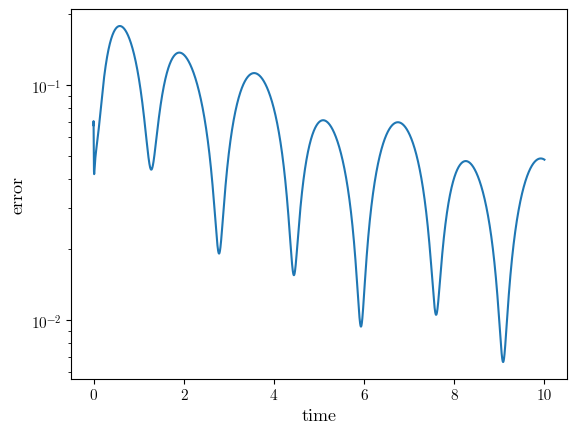

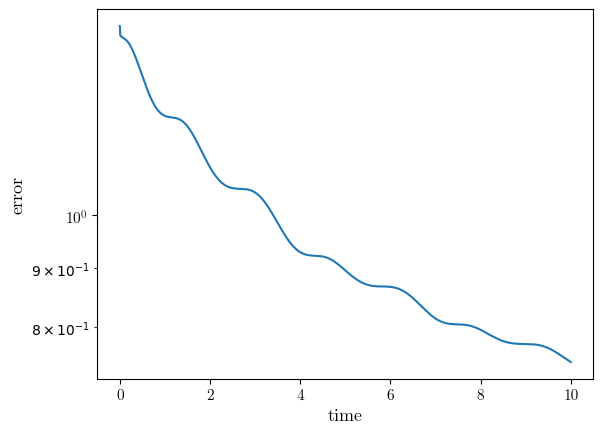

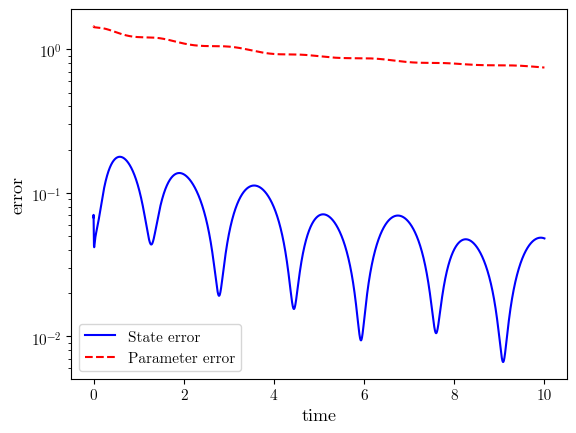

WebGuiWidget(layout=Layout(height='500px', width='100%'), value={'gui_settings': {'Objects': {'Wireframe': Fal…

WebGuiWidget(layout=Layout(height='500px', width='100%'), value={'gui_settings': {'Objects': {'Wireframe': Fal…

WebGuiWidget(layout=Layout(height='500px', width='100%'), value={'gui_settings': {'Objects': {'Wireframe': Fal…

WebGuiWidget(layout=Layout(height='500px', width='100%'), value={'gui_settings': {'Objects': {'Wireframe': Fal…

WebGuiWidget(layout=Layout(height='500px', width='100%'), value={'gui_settings': {'Objects': {'Wireframe': Fal…

WebGuiWidget(layout=Layout(height='500px', width='100%'), value={'gui_settings': {'Objects': {'Wireframe': Fal…

... (32 outputs left out)

9.9959999999999/1//

WebGuiWidget(layout=Layout(height='500px', width='100%'), value={'gui_settings': {}, 'ngsolve_version': '6.2.2…

WebGuiWidget(layout=Layout(height='500px', width='100%'), value={'gui_settings': {}, 'ngsolve_version': '6.2.2…

9.997999999999898/noiselevel: 0.03


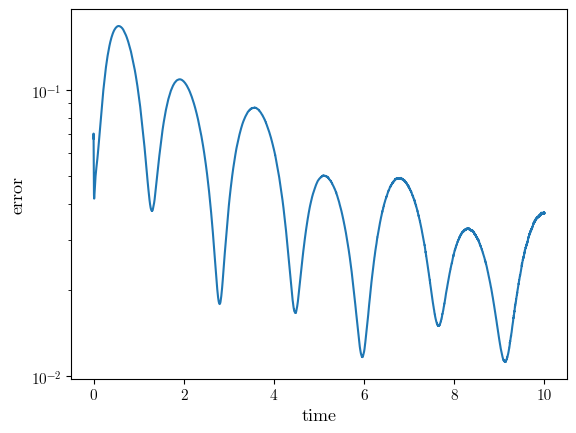

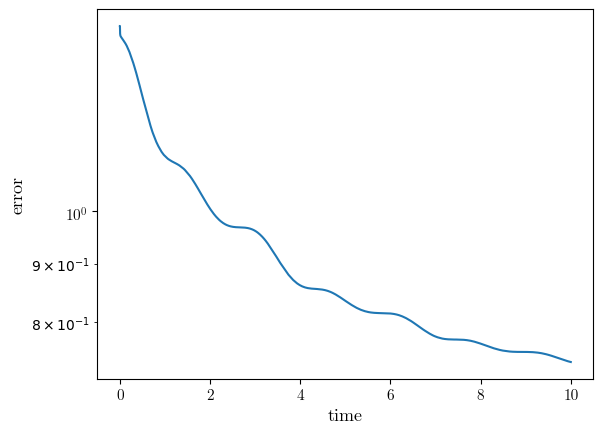

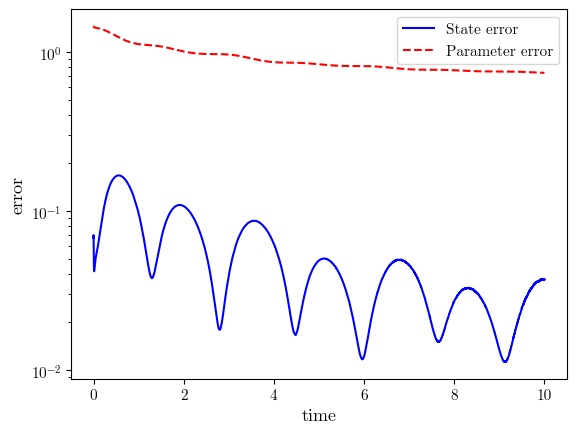

WebGuiWidget(layout=Layout(height='500px', width='100%'), value={'gui_settings': {'Objects': {'Wireframe': Fal…

WebGuiWidget(layout=Layout(height='500px', width='100%'), value={'gui_settings': {'Objects': {'Wireframe': Fal…

WebGuiWidget(layout=Layout(height='500px', width='100%'), value={'gui_settings': {'Objects': {'Wireframe': Fal…

WebGuiWidget(layout=Layout(height='500px', width='100%'), value={'gui_settings': {'Objects': {'Wireframe': Fal…

WebGuiWidget(layout=Layout(height='500px', width='100%'), value={'gui_settings': {'Objects': {'Wireframe': Fal…

WebGuiWidget(layout=Layout(height='500px', width='100%'), value={'gui_settings': {'Objects': {'Wireframe': Fal…

WebGuiWidget(layout=Layout(height='500px', width='100%'), value={'gui_settings': {}, 'ngsolve_version': '6.2.2…

WebGuiWidget(layout=Layout(height='500px', width='100%'), value={'gui_settings': {}, 'ngsolve_version': '6.2.2…

In [ ]:
# set up a joint finite element space for updating u and q together
X = FESpace([Ufes,Qfes])
u, q = X.TrialFunction()
v, s = X.TestFunction()
# MRAS (method for reconstruction) loop over noise levels
for noise_level in [0,0.03]:  #different noise levels
    counter = 1
    # Initial u and q
    gfu.Set(u_exact[0])
    gfq.Set(
        IfPos(x - (-1.15), 1, 0) *
        IfPos(1.15 - x, 1, 0) *
        IfPos(y - (-1.15), 1, 0) *
        IfPos(1.15 - y, 1, 0)
    )
    #initial error computation
    error_u = []#norm(gfu-u_exact[0],mesh)]
    error_q = []#norm(gfq-q_exact,mesh)]
    gf = GridFunction(X)
    t.Set(0)
    z_old.Set(CF(1))
    series_gfu, saved_gfu, saved_gfq = [],[],[]
    series_gfu.append(gfu.vec.FV().NumPy().copy())
    series_gfq = []
    series_gfq.append(gfq.vec.FV().NumPy().copy())
    while t < tend-2*dt:
        print("\r",t.Get(),"/",sep="",end="")
        # Get updated data z and g and compute time derivative zt
        z =  add_noise(u_exact[counter],noise_level,Ufes,mesh, 12)
        zt = GridFunction(Ufes)
        zt.vec.data = z.vec.Copy()
        zt.vec.data -= z_old.vec.Copy()#u_exact_dt[int(t.Get()/dt)]#
        zt.vec.data /= dt
        #g = zt + f(q_exact, u_exact[counter]) #manual forcing
        g = GridFunction(Ufes)
        g.Set(coef_f)#.vec.data = coef_f.vec.Copy() # gaussian
        
        a = BilinearForm(X)
        res = LinearForm(X)

        #joint solve
        #q equation
        a += q * s * dx

        res += gfq * s * dx
        res += dt * Grad(z_old)*(Grad(gfu)-Grad(z_old)) * s * dx# ##########check this

        # u equation
        a += u * v * dx 
        a += dt * Grad(u) * Grad(v) * dx
        a += dt * q * Grad(z) * Grad(v) * dx#Grad(z)?? 
        #a += dt * sigma * q * Grad(z) * Grad(s) * dx
        
        res += gfu * v * dx
        res += dt * (g-z+z*z) * v * dx
        res += dt * Grad(z) * Grad(v) * dx

        #res += -dt * sigma * gfq * Grad(z_old) * Grad(s) * dx#Grad(z)?? 
        #res += -dt * sigma * (zt+z_old-z_old*z_old-g) * s * dx
        a.Assemble()
        res.Assemble()
        
        c = Preconditioner(a,"local")   #<- Jacobi preconditioner
        c.Update()
        solvers.BVP(bf=a, lf=res, gf=gf, pre=c, print = False)
        gfu.Set(gf.components[0])
        error_q.append(norm(gfq-q_exact,mesh))
        if counter%100==0: saved_gfq.append(gfq.vec.FV().NumPy().copy())
        gfq.Set(gf.components[1])         
        error_u.append(norm(gfu-u_exact[counter],mesh))
        if counter%100==0: saved_gfu.append(gfu.vec.FV().NumPy().copy())
        t += dt    # Update time
        z_old.vec.data = z.vec.Copy()
        counter +=1
        if counter in [1,5,10,25,50,75,100,200, 500,1500,5000, tsteps-2]:
            Draw(gfu)
            series_gfu.append(gfu.vec.FV().NumPy().copy())
            Draw(gfq)
            series_gfq.append(gfq.vec.FV().NumPy().copy())

    print("noiselevel: "+str(noise_level))
    plot_error(tstart,tend,tsteps,noise_level,error_u,error_q)
    draw_gridfuncs (tsteps,u_exact,q_exact,gfu,gfq,mesh,umin, umax, qmin, qmax)
    save (mesh,noise_level,series_gfu,series_gfq)   
    save_diff(u_exact,q_exact,gfu, gfq, noise_level)

In [ ]:
Draw(u_exact[tsteps-1]-gfu,mesh, settings={"Objects": {"Wireframe": False}})
Draw(q_exact-gfq,mesh, settings={"Objects": {"Wireframe": False}}, min = -1, max = 1)

WebGuiWidget(layout=Layout(height='500px', width='100%'), value={'gui_settings': {'Objects': {'Wireframe': Fal…

WebGuiWidget(layout=Layout(height='500px', width='100%'), value={'gui_settings': {'Objects': {'Wireframe': Fal…

BaseWebGuiScene

In [9]:
mesh = Mesh("mesh.vol")
fes_q = L2(mesh, order=0)
fes_u = H1(mesh, order=3)
gfq_diff = GridFunction(fes_q)
gfq_diff.vec.FV().NumPy()[:] = np.load("difference_q0.0.npy") # array of the grid functions saved after each iteration
gfu_diff = GridFunction(fes_u)
gfu_diff.vec.FV().NumPy()[:] = np.load("difference_u0.0.npy")
Draw(gfu_diff)

FileNotFoundError: [Errno 2] No such file or directory: 'difference_q0.0.npy'

In [11]:
Draw(coef_0,mesh)

WebGuiWidget(layout=Layout(height='500px', width='100%'), value={'gui_settings': {}, 'ngsolve_version': '6.2.2…

BaseWebGuiScene